In [ ]:
import pandas as pd
import numpy as np

In [ ]:
data = pd.read_csv('/content/drive/MyDrive/tugas 1 pengembangan data/dataset_penjualan_kedai_kopi_raw.csv')

data.head()

,Transaction_ID,Transaction_Date,Customer_Age,Gender,Product,Quantity,Price_Per_Item,Payment_Method,Customer_Type,Total_Amount
0,TR001,2026-10-21,47.0,Male,Mocha,1.0,26000.0,QRIS,Regular,26000
1,TR002,2026-10-27,51.0,Male,Mocha,1.0,26000.0,Credit Card,New,26000
2,TR003,2026-10-08,32.0,female,Americano,2.0,18000.0,E-Wallet,Member,36000
3,TR004,2026-10-03,44.0,Male,Ice Latte,2.0,25000.0,Debit,New,50000
4,TR005,2026-10-28,47.0,Male,Matcha,2.0,23000.0,Debit,Member,46000


In [ ]:
data.shape

(123, 10)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123 entries, 0 to 122
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction_ID    123 non-null    object 
 1   Transaction_Date  123 non-null    object 
 2   Customer_Age      118 non-null    float64
 3   Gender            120 non-null    object 
 4   Product           121 non-null    object 
 5   Quantity          120 non-null    object 
 6   Price_Per_Item    121 non-null    float64
 7   Payment_Method    121 non-null    object 
 8   Customer_Type     121 non-null    object 
 9   Total_Amount      123 non-null    int64  
dtypes: float64(2), int64(1), object(7)
memory usage: 9.7+ KB


In [ ]:
data.describe()

,Customer_Age,Price_Per_Item,Total_Amount
count,118.000000,121.000000,123.000000
mean,38.728814,30867.760331,35195.113821
std,15.922709,88909.876937,19548.881035
min,-4.000000,16000.000000,-5000.000000
25%,28.000000,22000.000000,22500.000000
50%,42.000000,23000.000000,26000.000000
75%,48.000000,25000.000000,46000.000000
max,150.000000,999999.000000,104000.000000


In [ ]:
data.describe(include='all')

,Transaction_ID,Transaction_Date,Customer_Age,Gender,Product,Quantity,Price_Per_Item,Payment_Method,Customer_Type,Total_Amount
count,123,123,118.000000,120,121,120,121.000000,121,121,123.000000
unique,120,33,NaN,7,8,6,NaN,9,3,NaN
top,TR021,2026-10-03,NaN,Female,Cappuccino,1.0,NaN,Credit Card,Member,NaN
freq,2,8,NaN,64,21,69,NaN,31,45,NaN
mean,NaN,NaN,38.728814,NaN,NaN,NaN,30867.760331,NaN,NaN,35195.113821
std,NaN,NaN,15.922709,NaN,NaN,NaN,88909.876937,NaN,NaN,19548.881035
min,NaN,NaN,-4.000000,NaN,NaN,NaN,16000.000000,NaN,NaN,-5000.000000
25%,NaN,NaN,28.000000,NaN,NaN,NaN,22000.000000,NaN,NaN,22500.000000
50%,NaN,NaN,42.000000,NaN,NaN,NaN,23000.000000,NaN,NaN,26000.000000
75%,NaN,NaN,48.000000,NaN,NaN,NaN,25000.000000,NaN,NaN,46000.000000


## **Identifikasi Missing Value**

In [ ]:
data.isnull().sum()

,0
Transaction_ID,0
Transaction_Date,0
Customer_Age,5
Gender,3
Product,2
Quantity,3
Price_Per_Item,2
Payment_Method,2
Customer_Type,2
Total_Amount,0


In [ ]:
data[data.isnull().any(axis=1)]

,Transaction_ID,Transaction_Date,Customer_Age,Gender,Product,Quantity,Price_Per_Item,Payment_Method,Customer_Type,Total_Amount
7,TR008,2026-10-18,NaN,Female,Ice Latte,1.0,25000.0,Cash,Regular,25000
13,TR014,2026-10-04,54.0,Female,Mocha,NaN,26000.0,Credit Card,Member,26000
16,TR017,2026-10-01,28.0,NaN,Ice Latte,2.0,25000.0,Cash,Regular,50000
22,TR023,2026-10-23,NaN,Female,Americano,1.0,18000.0,E-Wallet,Member,18000
29,TR030,2026-10-24,37.0,Male,NaN,1.0,24000.0,Cash,Member,24000
31,TR032,2026-10-18,22.0,Male,Americano,2.0,NaN,Cash,Regular,36000
37,TR038,2026-10-04,50.0,Male,Ice Latte,NaN,25000.0,Credit Card,New,50000
42,TR043,2026-10-08,18.0,Male,Cold Brew,1.0,24000.0,NaN,Regular,24000
46,TR047,2026-10-15,NaN,Male,Cappuccino,2.0,22000.0,Debit,New,44000
54,TR055,2026-10-13,53.0,Male,Caramel Macchiato,3.0,28000.0,E-Wallet,NaN,84000


In [ ]:
kolom_numerik = [
    'Customer_Age',
    'Quantity',
    'Price_Per_Item',
    'Total_Amount'
]

data[kolom_numerik].describe()

,Customer_Age,Price_Per_Item,Total_Amount
count,118.000000,121.000000,123.000000
mean,38.728814,30867.760331,35195.113821
std,15.922709,88909.876937,19548.881035
min,-4.000000,16000.000000,-5000.000000
25%,28.000000,22000.000000,22500.000000
50%,42.000000,23000.000000,26000.000000
75%,48.000000,25000.000000,46000.000000
max,150.000000,999999.000000,104000.000000


In [ ]:
data_clean = data.copy()

kolom_imputasi_numerik = [
    'Customer_Age',
    'Quantity',
    'Price_Per_Item'
]

for kolom in kolom_imputasi_numerik:
    median_value = data_clean[kolom].median()
    data_clean[kolom] = data_clean[kolom].fillna(median_value)

data_clean[kolom_imputasi_numerik].isnull().sum()

,0
Customer_Age,0
Quantity,0
Price_Per_Item,0


In [ ]:
kolom_kategorik = [
    'Gender',
    'Product',
    'Payment_Method',
    'Customer_Type'
]

for kolom in kolom_kategorik:
    print(f"\nFrekuensi {kolom}:")
    print(data[kolom].value_counts(dropna=False))


Frekuensi Gender:
Gender
Female     64
Male       51
NaN         3
female      1
F           1
MALE        1
m           1
Female      1
Name: count, dtype: int64

Frekuensi Product:
Product
Cappuccino           21
Americano            20
Ice Latte            16
Cold Brew            15
Mocha                14
Caramel Macchiato    14
Matcha               11
Espresso             10
NaN                   2
Name: count, dtype: int64

Frekuensi Payment_Method:
Payment_Method
Credit Card    31
E-Wallet       26
Cash           24
QRIS           19
Debit          17
NaN             2
qris            1
QRIS            1
E-Wallet        1
e-wallet        1
Name: count, dtype: int64

Frekuensi Customer_Type:
Customer_Type
Member     45
Regular    38
New        38
NaN         2
Name: count, dtype: int64


In [ ]:
for kolom in kolom_kategorik:
    modus = data_clean[kolom].mode()[0]
    data_clean[kolom] = data_clean[kolom].fillna(modus)

data_clean[kolom_kategorik].isnull().sum()

,0
Gender,0
Product,0
Payment_Method,0
Customer_Type,0


# **Mengatasi Data Duplikat**

In [ ]:
data.duplicated().sum()

np.int64(3)

In [ ]:
data[data.duplicated(keep=False)]

,Transaction_ID,Transaction_Date,Customer_Age,Gender,Product,Quantity,Price_Per_Item,Payment_Method,Customer_Type,Total_Amount
20,TR021,2026-10-22,48.0,Female,Mocha,1.0,26000.0,Cash,Regular,26000
48,TR049,2026-10-28,54.0,Male,Caramel Macchiato,1.0,28000.0,Cash,New,28000
90,TR091,2026-10-26,45.0,Male,Americano,1.0,18000.0,Credit Card,New,18000
120,TR021,2026-10-22,48.0,Female,Mocha,1.0,26000.0,Cash,Regular,26000
121,TR049,2026-10-28,54.0,Male,Caramel Macchiato,1.0,28000.0,Cash,New,28000
122,TR091,2026-10-26,45.0,Male,Americano,1.0,18000.0,Credit Card,New,18000


In [ ]:
jumlah_sebelum = len(data_clean)

data_clean = data_clean.drop_duplicates()

jumlah_sesudah = len(data_clean)

print("Jumlah baris sebelum:", jumlah_sebelum)
print("Jumlah baris sesudah:", jumlah_sesudah)
print("Duplikat yang dihapus:", jumlah_sebelum - jumlah_sesudah)

Jumlah baris sebelum: 123
Jumlah baris sesudah: 120
Duplikat yang dihapus: 3


Mengatasi Inconsistent **Data**

In [ ]:
for kolom in kolom_kategorik:
    print(f"\nKategori pada {kolom}:")
    print(data_clean[kolom].unique())


Kategori pada Gender:
['Male' 'female' 'Female' 'F' 'MALE' 'm' 'Female ']

Kategori pada Product:
['Mocha' 'Americano' 'Ice Latte' 'Matcha' 'Cappuccino' 'Espresso'
 'Caramel Macchiato' 'Cold Brew']

Kategori pada Payment_Method:
['QRIS' 'Credit Card' 'E-Wallet' 'Debit' 'Cash' 'qris' 'QRIS ' 'E-Wallet '
 'e-wallet']

Kategori pada Customer_Type:
['Regular' 'New' 'Member']


In [ ]:
data_clean['Gender'] = (
    data_clean['Gender']
    .astype('string')
    .str.strip()
    .str.lower()
)

data_clean['Gender'] = data_clean['Gender'].replace({
    'female': 'Female',
    'f': 'Female',
    'male': 'Male',
    'm': 'Male'
})

data_clean['Gender'].value_counts()

,count
Gender,
Female,69
Male,51


In [ ]:
data_clean['Payment_Method'] = (
    data_clean['Payment_Method']
    .astype('string')
    .str.strip()
    .str.lower()
)

data_clean['Payment_Method'] = data_clean['Payment_Method'].replace({
    'qris': 'QRIS',
    'cash': 'Cash',
    'debit': 'Debit',
    'credit card': 'Credit Card',
    'e-wallet': 'E-Wallet'
})

data_clean['Payment_Method'].value_counts()

,count
Payment_Method,
Credit Card,32
E-Wallet,28
Cash,22
QRIS,21
Debit,17


In [ ]:
data_clean['Customer_Type'] = (
    data_clean['Customer_Type']
    .astype('string')
    .str.strip()
    .str.lower()
)

data_clean['Customer_Type'] = data_clean['Customer_Type'].replace({
    'new': 'New',
    'regular': 'Regular',
    'member': 'Member'
})

data_clean['Customer_Type'].value_counts()

,count
Customer_Type,
Member,47
Regular,37
New,36


In [ ]:
daftar_produk = [
    'Ice Latte',
    'Americano',
    'Matcha',
    'Cappuccino',
    'Mocha',
    'Caramel Macchiato',
    'Espresso',
    'Cold Brew'
]

mapping_produk = {
    produk.lower(): produk
    for produk in daftar_produk
}

data_clean['Product'] = (
    data_clean['Product']
    .astype('string')
    .str.strip()
    .str.lower()
    .map(mapping_produk)
)

data_clean['Product'].value_counts()

,count
Product,
Cappuccino,23
Americano,19
Ice Latte,16
Cold Brew,15
Caramel Macchiato,13
Mocha,13
Matcha,11
Espresso,10


**Mengatasi Kesalahan Format Tanggal**

In [ ]:
data_clean['Transaction_Date'].unique()

array(['2026-10-21', '2026-10-27', '2026-10-08', '2026-10-03',
       '2026-10-28', '01/10/2026', '2026-10-26', '2026-10-18',
       '2026-10-29', '2026-10-12', '2026-10-09', '2026-10-04',
       '2026-10-23', '2026-10-01', '2026-10-07', '2026-10-22',
       '10-02-2026', '2026-10-17', '2026-10-13', '2026-10-24',
       '2026-10-06', '2026-10-15', '2026-10-25', '2026-10-16',
       '2026-10-10', '2026-10-30', '2026-10-05', '2026/10/15',
       '2026-10-02', '2026-10-31', '2026-10-11', '2026-10-19',
       '31/10/2026'], dtype=object)

In [ ]:
data_clean['Transaction_Date'] = pd.to_datetime(
    data_clean['Transaction_Date'],
    format='mixed',
    errors='coerce',
    dayfirst=True
)

data_clean['Transaction_Date'].head(10)

,Transaction_Date
0,2026-10-21
1,2026-10-27
2,2026-10-08
3,2026-10-03
4,2026-10-28
5,2026-10-01
6,2026-10-26
7,2026-10-18
8,2026-10-29
9,2026-10-12


In [ ]:
data_clean['Transaction_Date'].dt.strftime('%Y-%m-%d').head(10)

,Transaction_Date
0,2026-10-21
1,2026-10-27
2,2026-10-08
3,2026-10-03
4,2026-10-28
5,2026-10-01
6,2026-10-26
7,2026-10-18
8,2026-10-29
9,2026-10-12


**Mengatasi Kesalahan Tipe Data**

In [ ]:
kolom_numerik = [
    'Customer_Age',
    'Quantity',
    'Price_Per_Item',
    'Total_Amount'
]

for kolom in kolom_numerik:
    data_clean[kolom] = pd.to_numeric(
        data_clean[kolom],
        errors='coerce'
    )

data_clean[kolom_numerik].dtypes

,0
Customer_Age,float64
Quantity,float64
Price_Per_Item,float64
Total_Amount,int64


**Mengatasi Data Tidak Valid**

In [ ]:
data_clean.loc[
    (data_clean['Customer_Age'] < 1) |
    (data_clean['Customer_Age'] > 100),
    'Customer_Age'
] = np.nan

data_clean['Customer_Age'].describe()

,Customer_Age
count,118.000000
mean,38.025424
std,11.357788
min,17.000000
25%,28.250000
50%,42.000000
75%,47.750000
max,55.000000


In [ ]:
data_clean.loc[
    data_clean['Quantity'] <= 0,
    'Quantity'
] = np.nan

data_clean['Quantity'].describe()

,Quantity
count,119.000000
mean,1.571429
std,0.808550
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,4.000000


In [ ]:
data_clean.loc[
    data_clean['Price_Per_Item'] <= 0,
    'Price_Per_Item'
] = np.nan

data_clean['Price_Per_Item'].describe()

,Price_Per_Item
count,120.000000
mean,30908.325000
std,89279.188833
min,16000.000000
25%,22000.000000
50%,23000.000000
75%,25000.000000
max,999999.000000


In [ ]:
data_clean.loc[
    data_clean['Total_Amount'] <= 0,
    'Total_Amount'
] = np.nan

data_clean['Total_Amount'].describe()

,Total_Amount
count,119.000000
mean,35815.117647
std,19426.084247
min,9999.000000
25%,23000.000000
50%,26000.000000
75%,47000.000000
max,104000.000000


In [ ]:
data_clean.isnull().sum()

,0
Transaction_ID,0
Transaction_Date,0
Customer_Age,2
Gender,0
Product,0
Quantity,1
Price_Per_Item,0
Payment_Method,0
Customer_Type,0
Total_Amount,1


**Penanganan Missing Value Berdasarkan Statistik Deskriptif**

In [ ]:
data_clean[kolom_numerik].describe()

,Customer_Age,Quantity,Price_Per_Item,Total_Amount
count,118.000000,119.000000,120.000000,119.000000
mean,38.025424,1.571429,30908.325000,35815.117647
std,11.357788,0.808550,89279.188833,19426.084247
min,17.000000,1.000000,16000.000000,9999.000000
25%,28.250000,1.000000,22000.000000,23000.000000
50%,42.000000,1.000000,23000.000000,26000.000000
75%,47.750000,2.000000,25000.000000,47000.000000
max,55.000000,4.000000,999999.000000,104000.000000


In [ ]:
for kolom in kolom_kategorik:
    print(f"\nStatistik frekuensi {kolom}:")
    print(data_clean[kolom].value_counts(dropna=False))


Statistik frekuensi Gender:
Gender
Female    69
Male      51
Name: count, dtype: Int64

Statistik frekuensi Product:
Product
Cappuccino           23
Americano            19
Ice Latte            16
Cold Brew            15
Caramel Macchiato    13
Mocha                13
Matcha               11
Espresso             10
Name: count, dtype: int64

Statistik frekuensi Payment_Method:
Payment_Method
Credit Card    32
E-Wallet       28
Cash           22
QRIS           21
Debit          17
Name: count, dtype: Int64

Statistik frekuensi Customer_Type:
Customer_Type
Member     47
Regular    37
New        36
Name: count, dtype: Int64


In [ ]:
kolom_imputasi_numerik = [
    'Customer_Age',
    'Quantity',
    'Price_Per_Item'
]

for kolom in kolom_imputasi_numerik:
    median_value = data_clean[kolom].median()

    print(f"Median {kolom}: {median_value}")

    data_clean[kolom] = data_clean[kolom].fillna(median_value)

Median Customer_Age: 42.0
Median Quantity: 1.0
Median Price_Per_Item: 23000.0


In [ ]:
for kolom in kolom_kategorik:
    modus = data_clean[kolom].mode()[0]

    print(f"Modus {kolom}: {modus}")

    data_clean[kolom] = data_clean[kolom].fillna(modus)

Modus Gender: Female
Modus Product: Cappuccino
Modus Payment_Method: Credit Card
Modus Customer_Type: Member


In [ ]:
data_clean.isnull().sum()

,0
Transaction_ID,0
Transaction_Date,0
Customer_Age,0
Gender,0
Product,0
Quantity,0
Price_Per_Item,0
Payment_Method,0
Customer_Type,0
Total_Amount,1


**Deteksi dan Penanganan Outlier**

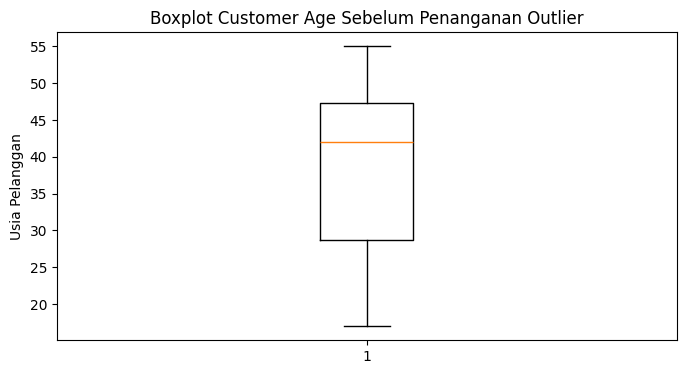

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.boxplot(data_clean['Customer_Age'].dropna())
plt.title('Boxplot Customer Age Sebelum Penanganan Outlier')
plt.ylabel('Usia Pelanggan')
plt.show()

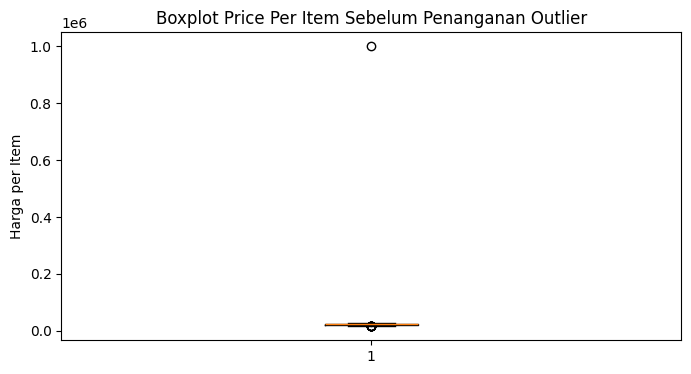

In [ ]:
plt.figure(figsize=(8, 4))
plt.boxplot(data_clean['Price_Per_Item'].dropna())
plt.title('Boxplot Price Per Item Sebelum Penanganan Outlier')
plt.ylabel('Harga per Item')
plt.show()

In [ ]:
def cek_outlier(data, kolom):
    Q1 = data[kolom].quantile(0.25)
    Q3 = data[kolom].quantile(0.75)

    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    outlier = data[
        (data[kolom] < batas_bawah) |
        (data[kolom] > batas_atas)
    ]

    print("Variabel:", kolom)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Batas bawah:", batas_bawah)
    print("Batas atas:", batas_atas)
    print("Jumlah outlier:", len(outlier))

    return outlier

In [ ]:
outlier_age = cek_outlier(data_clean, 'Customer_Age')

outlier_age

Variabel: Customer_Age
Q1: 28.75
Q3: 47.25
IQR: 18.5
Batas bawah: 1.0
Batas atas: 75.0
Jumlah outlier: 0


,Transaction_ID,Transaction_Date,Customer_Age,Gender,Product,Quantity,Price_Per_Item,Payment_Method,Customer_Type,Total_Amount


In [ ]:
outlier_price = cek_outlier(data_clean, 'Price_Per_Item')

outlier_price

Variabel: Price_Per_Item
Q1: 22000.0
Q3: 25000.0
IQR: 3000.0
Batas bawah: 17500.0
Batas atas: 29500.0
Jumlah outlier: 11


,Transaction_ID,Transaction_Date,Customer_Age,Gender,Product,Quantity,Price_Per_Item,Payment_Method,Customer_Type,Total_Amount
15,TR016,2026-10-23,23.0,Female,Espresso,1.0,16000.0,Credit Card,Member,16000.0
23,TR024,2026-10-23,22.0,Female,Espresso,1.0,16000.0,QRIS,New,16000.0
65,TR066,2026-10-15,46.0,Male,Espresso,2.0,16000.0,QRIS,Member,32000.0
76,TR077,2026-10-27,24.0,Male,Espresso,1.0,16000.0,Debit,Member,16000.0
86,TR087,2026-10-05,47.0,Male,Espresso,1.0,16000.0,Credit Card,Member,16000.0
94,TR095,2026-10-05,53.0,Female,Espresso,2.0,16000.0,Cash,Regular,32000.0
101,TR102,2026-10-17,42.0,Female,Ice Latte,4.0,999999.0,E-Wallet,Member,100000.0
106,TR107,2026-10-22,43.0,Male,Espresso,1.0,16000.0,E-Wallet,New,16000.0
108,TR109,2026-10-12,30.0,Male,Espresso,3.0,16000.0,QRIS,Member,48000.0
109,TR110,2026-10-31,47.0,Female,Espresso,1.0,16000.0,Credit Card,Regular,16000.0


In [ ]:
def iqr_capping(data, kolom):
    Q1 = data[kolom].quantile(0.25)
    Q3 = data[kolom].quantile(0.75)

    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    data[kolom] = data[kolom].clip(
        lower=batas_bawah,
        upper=batas_atas
    )

    return data

In [ ]:
data_clean = iqr_capping(data_clean, 'Customer_Age')
data_clean = iqr_capping(data_clean, 'Price_Per_Item')

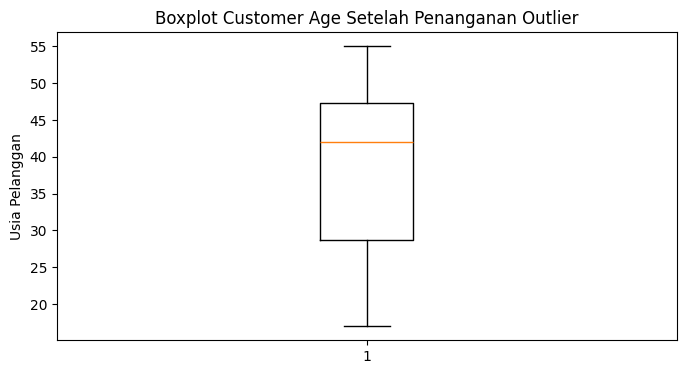

In [ ]:
plt.figure(figsize=(8, 4))
plt.boxplot(data_clean['Customer_Age'])
plt.title('Boxplot Customer Age Setelah Penanganan Outlier')
plt.ylabel('Usia Pelanggan')
plt.show()

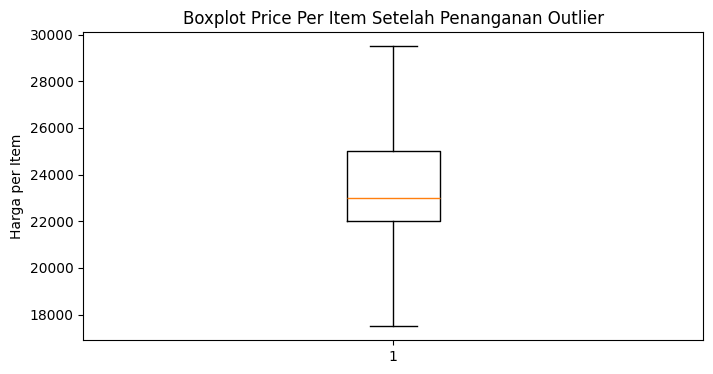

In [ ]:
plt.figure(figsize=(8, 4))
plt.boxplot(data_clean['Price_Per_Item'])
plt.title('Boxplot Price Per Item Setelah Penanganan Outlier')
plt.ylabel('Harga per Item')
plt.show()

**Memeriksa Ketidaksesuaian Total Transaksi**

In [ ]:
data_clean['Total_Seharusnya'] = (
    data_clean['Quantity'] * data_clean['Price_Per_Item']
)

data_clean['Selisih_Total'] = (
    data_clean['Total_Amount'] - data_clean['Total_Seharusnya']
)

data_clean[
    data_clean['Selisih_Total'] != 0
][[
    'Transaction_ID',
    'Quantity',
    'Price_Per_Item',
    'Total_Amount',
    'Total_Seharusnya',
    'Selisih_Total'
]]

,Transaction_ID,Quantity,Price_Per_Item,Total_Amount,Total_Seharusnya,Selisih_Total
15,TR016,1.0,17500.0,16000.0,17500.0,-1500.0
23,TR024,1.0,17500.0,16000.0,17500.0,-1500.0
31,TR032,2.0,23000.0,36000.0,46000.0,-10000.0
34,TR035,4.0,22000.0,9999.0,88000.0,-78001.0
37,TR038,1.0,25000.0,50000.0,25000.0,25000.0
65,TR066,2.0,17500.0,32000.0,35000.0,-3000.0
73,TR074,1.0,23000.0,25000.0,23000.0,2000.0
76,TR077,1.0,17500.0,16000.0,17500.0,-1500.0
86,TR087,1.0,17500.0,16000.0,17500.0,-1500.0
87,TR088,1.0,25000.0,50000.0,25000.0,25000.0


In [ ]:
data_clean['Total_Amount'] = (
    data_clean['Quantity'] * data_clean['Price_Per_Item']
)

data_clean[['Quantity', 'Price_Per_Item', 'Total_Amount']].head(10)

,Quantity,Price_Per_Item,Total_Amount
0,1.0,26000.0,26000.0
1,1.0,26000.0,26000.0
2,2.0,18000.0,36000.0
3,2.0,25000.0,50000.0
4,2.0,23000.0,46000.0
5,4.0,18000.0,72000.0
6,1.0,23000.0,23000.0
7,1.0,25000.0,25000.0
8,1.0,18000.0,18000.0
9,2.0,23000.0,46000.0


In [ ]:
data_clean.isnull().sum()

,0
Transaction_ID,0
Transaction_Date,0
Customer_Age,0
Gender,0
Product,0
Quantity,0
Price_Per_Item,0
Payment_Method,0
Customer_Type,0
Total_Amount,0


In [ ]:
data_clean.duplicated().sum()

np.int64(0)

In [ ]:
data_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 120 entries, 0 to 119
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction_ID    120 non-null    object        
 1   Transaction_Date  120 non-null    datetime64[ns]
 2   Customer_Age      120 non-null    float64       
 3   Gender            120 non-null    string        
 4   Product           120 non-null    object        
 5   Quantity          120 non-null    float64       
 6   Price_Per_Item    120 non-null    float64       
 7   Payment_Method    120 non-null    string        
 8   Customer_Type     120 non-null    string        
 9   Total_Amount      120 non-null    float64       
 10  Total_Seharusnya  120 non-null    float64       
 11  Selisih_Total     119 non-null    float64       
dtypes: datetime64[ns](1), float64(6), object(2), string(3)
memory usage: 12.2+ KB


In [ ]:
data_clean.describe()

,Transaction_Date,Customer_Age,Quantity,Price_Per_Item,Total_Amount,Total_Seharusnya,Selisih_Total
count,120,120.000000,120.000000,120.000000,120.000000,120.000000,119.000000
mean,2026-10-13 01:36:00,38.091667,1.566667,22945.833333,36141.666667,36141.666667,-394.966387
min,2026-02-10 00:00:00,17.000000,1.000000,17500.000000,17500.000000,17500.000000,-78001.000000
25%,2026-10-06 00:00:00,28.750000,1.000000,22000.000000,23000.000000,23000.000000,0.000000
50%,2026-10-16 00:00:00,42.000000,1.000000,23000.000000,26000.000000,26000.000000,0.000000
75%,2026-10-23 00:00:00,47.250000,2.000000,25000.000000,46000.000000,46000.000000,0.000000
max,2026-10-31 00:00:00,55.000000,4.000000,29500.000000,118000.000000,118000.000000,28000.000000
std,NaN,11.273525,0.806834,3373.647151,20210.570424,20210.570424,8527.916364


In [ ]:
print("===== DATA SEBELUM PREPROCESSING =====")
print("Jumlah baris:", data.shape[0])
print("Jumlah kolom:", data.shape[1])
print("Total missing value:", data.isnull().sum().sum())
print("Total duplikat:", data.duplicated().sum())

print("\n===== DATA SETELAH PREPROCESSING =====")
print("Jumlah baris:", data_clean.shape[0])
print("Jumlah kolom:", data_clean.shape[1])
print("Total missing value:", data_clean.isnull().sum().sum())
print("Total duplikat:", data_clean.duplicated().sum())

===== DATA SEBELUM PREPROCESSING =====
Jumlah baris: 123
Jumlah kolom: 10
Total missing value: 19
Total duplikat: 3

===== DATA SETELAH PREPROCESSING =====
Jumlah baris: 120
Jumlah kolom: 12
Total missing value: 1
Total duplikat: 0


**Menyimpan Dataset Hasil Preprocessing**

In [ ]:
data_clean.to_csv(
    'dataset_penjualan_kedai_kopi_cleaned.csv',
    index=False
)

print("Dataset berhasil disimpan!")

Dataset berhasil disimpan!


In [ ]:
from google.colab import files

files.download('dataset_penjualan_kedai_kopi_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>